In [38]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

def sigmoid(z):
# YOUR CODE HERE
# Hint: use np.clip(z, -500, 500) to avoid overflow
  z_c  = np.clip(z, -500, 500)
  return  1/(1+np.exp(-z_c))

def sigmoid_derivative(a):
  return a * (1 - a)

In [39]:
def forward_pass(X, W1, b1, W2, b2, W3, b3):
# Layer 1
  Z1 = ( X @ W1 + b1)
  A1 =sigmoid(Z1)
# Layer 2
  Z2 = (A1 @ W2 + b2)
  A2 = sigmoid(Z2)
# Output layer
  Z3 = (A2 @ W3 + b3)
  A3 = sigmoid(Z3)

  return Z1, A1, Z2, A2, Z3, A3

In [ ]:


data      = np.load('D:\MVC-MLP-25I3109\data')
X_train   = data['x_train'].reshape(-1, 784) / 255.0   # (60000, 784)
Y_train   = data['y_train']                             # (60000,)  integers 0-9
X_test    = data['x_test'].reshape(-1, 784)  / 255.0   # (10000, 784)
Y_test    = data['y_test']                              # (10000,)  integers 0-9

X_train: (60000, 784)   Y_train: (60000,)
X_test : (10000, 784)   Y_test : (10000,)


In [40]:
def mse_loss(Y_true, Y_pred):
  return np.mean((Y_true - Y_pred)**2 )

In [41]:
def backpropagation(X, Y_true, Z1, A1, Z2, A2, Z3, A3, W1, W2, W3):

  m = X.shape[0]
# Output layer delta
  delta3 =  (-2*(Y_true - A3) * sigmoid_derivative(A3))
# Gradients for W3, b3
  dW3 = A2.T @ delta3 / m
  db3 = np.sum(delta3, axis=0, keepdims=True) / m
# Hidden layer 2 delta
  delta2 = (delta3 @ W3.T * sigmoid_derivative(A2))
# Gradients for W2, b2
  dW2 = A1.T @ delta2 / m
  db2 = np.sum(delta2, axis=0, keepdims=True) / m
# Hidden layer 1 delta
  delta1 = (delta2 @ W2.T * sigmoid_derivative(A1))
# Gradients for W1, b1
  dW1 = X.T @ delta1 / m
  db1 = np.sum(delta1 , axis=0, keepdims=True) / m
  return dW1, db1, dW2, db2, dW3, db3

In [42]:
def update_weights(W1, b1, W2, b2, W3, b3,dW1, db1, dW2, db2, dW3, db3,learning_rate):

  W1 = W1 - learning_rate * dW1
  b1 = b1 - learning_rate * db1
  W2 = W2 -  learning_rate*dW2
  b2 = b2 - learning_rate *db2
  W3 = W3 - learning_rate *dW3
  b3 = b3 - learning_rate *db3
  return W1, b1, W2, b2, W3, b3
# Return all updated weights and biases

In [43]:
# One-hot encode labels  →  shape (m, 10)
def one_hot(y, num_classes=10):
    m = y.shape[0]
    Y_oh = np.zeros((m, num_classes))
    Y_oh[np.arange(m), y] = 1.0
    return Y_oh

Y_train_oh = one_hot(Y_train)   # (60000, 10)
Y_test_oh  = one_hot(Y_test)    # (10000, 10)

print('Y_train_oh:', Y_train_oh.shape)
print('Example row (digit', Y_train[0], '):', Y_train_oh[0])

Y_train_oh: (60000, 10)
Example row (digit 5 ): [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [44]:
learning_rate = 0.1
epochs = 20
batch_size = 32
loss_history = []
np.random.seed(42)   # Reset seed so initialisation is always the same
W1 = np.random.uniform(-0.5, 0.5, (784, 128))
b1 = np.zeros((1, 128))

W2 = np.random.uniform(-0.5, 0.5, (128, 64))
b2 = np.zeros((1, 64))

W3 = np.random.uniform(-0.5, 0.5, (64, 10))
b3 = np.zeros((1, 10))
for epoch in range(epochs):
  i = 0

# Shuffle training data
  idx = np.random.permutation(X_train.shape[0])
  X_shuf = X_train[idx]
  Y_shuf = Y_train_oh[idx] # one-hot labels
# Mini-batch loop
  for start in range(0, X_train.shape[0], batch_size):
    X_batch = X_shuf[start : start + batch_size]
    Y_batch = Y_shuf[start : start + batch_size]


# Step 1: Forward pass
    Z1,A1,Z2,A2,Z3,A3 = forward_pass(X_batch, W1,b1,W2,b2,W3,b3)

# Step 2: Compute loss
    loss = mse_loss(Y_batch, A3)
# Step 3: Backpropagation
    dW1,db1,dW2,db2,dW3,db3 = backpropagation(X_batch, Y_batch, Z1,A1,Z2,A2,Z3,A3, W1,W2,W3)
# Step 4: Update weights
    W1,b1,W2,b2,W3,b3 = update_weights(W1,b1,W2,b2,W3,b3,dW1,db1,dW2,db2,dW3,db3, learning_rate)
    # print("Cycle" , i)
    i= i+1
# Record epoch loss
  _,_,_,_,_,A3_full = forward_pass(X_train,W1,b1,W2,b2,W3,b3)
  epoch_loss = mse_loss(Y_train_oh, A3_full)
  loss_history.append(epoch_loss)
  print(f"Epoch {epoch+1}/{epochs} Loss: {epoch_loss:.4f}")

Epoch 1/20 Loss: 0.0296
Epoch 2/20 Loss: 0.0208
Epoch 3/20 Loss: 0.0172
Epoch 4/20 Loss: 0.0153
Epoch 5/20 Loss: 0.0138
Epoch 6/20 Loss: 0.0127
Epoch 7/20 Loss: 0.0119
Epoch 8/20 Loss: 0.0111
Epoch 9/20 Loss: 0.0105
Epoch 10/20 Loss: 0.0100
Epoch 11/20 Loss: 0.0095
Epoch 12/20 Loss: 0.0091
Epoch 13/20 Loss: 0.0088
Epoch 14/20 Loss: 0.0084
Epoch 15/20 Loss: 0.0081
Epoch 16/20 Loss: 0.0078
Epoch 17/20 Loss: 0.0076
Epoch 18/20 Loss: 0.0073
Epoch 19/20 Loss: 0.0071
Epoch 20/20 Loss: 0.0069


In [45]:

def predict(X, W1, b1, W2, b2, W3, b3):
    """Return predicted class index (argmax of output layer) for each sample."""
    _, _, _, _, _, A3 = forward_pass(X, W1, b1, W2, b2, W3, b3)
    return np.argmax(A3, axis=1)   # (m,)


Y_pred_test = predict(X_test, W1, b1, W2, b2, W3, b3)
accuracy    = np.mean(Y_pred_test == Y_test) * 100.0

print('=' * 45)
print(f'  Test Accuracy (10,000 images): {accuracy:.2f} %')
print('=' * 45)


  Test Accuracy (10,000 images): 95.54 %


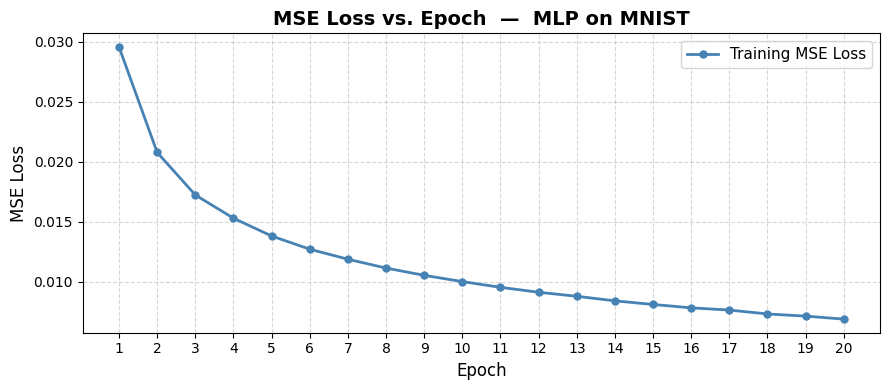

In [46]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(range(1, epochs + 1), loss_history,
        marker='o', markersize=5, linewidth=2,
        color='steelblue', label='Training MSE Loss')

ax.set_title('MSE Loss vs. Epoch  —  MLP on MNIST', fontsize=14, fontweight='bold')
ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('MSE Loss', fontsize=12)
ax.set_xticks(range(1, epochs + 1))
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(fontsize=11)

plt.tight_layout()
plt.savefig('loss_curve.png', dpi=150)
plt.show()
# print(f'Final training MSE: {loss_history[-1]:.4f}')=

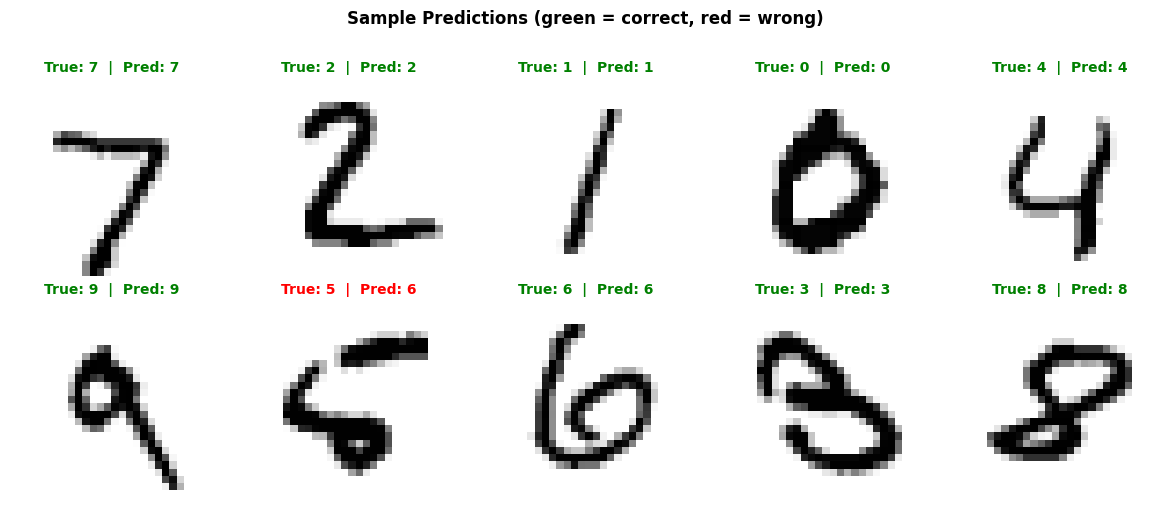

In [47]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()

shown = set()
plot_idx = 0

for i in range(len(X_test)):
    true_label = Y_test[i]
    if true_label not in shown:
        pred_label = Y_pred_test[i]
        img = X_test[i].reshape(28, 28)

        ax = axes[plot_idx]
        ax.imshow(img, cmap='gray_r')

        color = 'green' if pred_label == true_label else 'red'
        ax.set_title(f'True: {true_label}  |  Pred: {pred_label}',
                     fontsize=10, color=color, fontweight='bold')
        ax.axis('off')

        shown.add(true_label)
        plot_idx += 1

    if len(shown) == 10:
        break

fig.suptitle('Sample Predictions (green = correct, red = wrong)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('prediton.png', dpi=150, bbox_inches='tight')
plt.show()